# Ampara ML: risco de roubo e furto de celular por área, dia e horário em São Paulo

Global Solution 2026.2 FIAP, CitizenTech. Notebook executado de ponta a ponta com dados reais e públicos.
O notebook só chama funções do pacote `ampara_ml` (código em `ml/ampara_ml/`, 100 % testado); a lógica não mora aqui.

## 00 Ficha

**Pergunta de ML.** Dada uma área de cerca de 500 m × 500 m da capital paulista, um dia da semana e uma faixa de 3 horas,
qual a classe de risco (baixo, médio, alto) de roubo ou furto de celular no próximo trimestre, e com que probabilidade de ser alto?

**Integrantes** (parte de ML feita por Pedro Martins):

- Pedro Martins (ML)
- Vitor Cesarino Marchese

Os RMs estão no `integrantes.txt` da raiz do repositório.

**Uso no produto.** O `ml/saida/risco.csv` gerado aqui é lido pela API do Ampara e vira o mapa de risco do app: risco por área e horário, nunca por pessoa.

In [1]:
import sys
sys.path.insert(0, "..")

import platform
import numpy as np
import pandas as pd
import sklearn, xgboost, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from ampara_ml.config import SEED, DIR_SAIDA, RAIZ_ML
from ampara_ml.classes import calcular_cortes
from ampara_ml.divisao import cv_temporal
from ampara_ml.graficos import (grafico_busca, grafico_curva_aprendizado, grafico_importancia,
                                grafico_matriz_confusao, grafico_treino_teste)
from ampara_ml.exportar import gerar_risco, salvar_risco
from ampara_ml.modelos import (GRADE_RF, GRADE_XGB, N_COMBINACOES_RF, N_COMBINACOES_XGB, avaliar,
                               buscar_hiperparametros, curva_aprendizado, fabrica_rf, fabrica_xgb, treinar_final)
from ampara_ml.pipeline import ocorrencias_limpas, preparar_dados
from ampara_ml.ssp import COORD_MIN_FRACAO, decidir_resolucao

np.random.seed(SEED)
DIR_FIG = RAIZ_ML / "figuras"
DIR_FIG.mkdir(exist_ok=True)
print("semente:", SEED)
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| matplotlib", matplotlib.__version__)

semente: 42
python 3.13.15 | numpy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1 | xgboost 3.4.1 | matplotlib 3.11.2


## 01 Problema e dados reais

Todos os dados são reais e públicos. Nenhum dado pessoal entra no modelo: a unidade é a **área** (célula de grade), nunca uma pessoa.

| Fonte | O que traz | Link | Período |
|---|---|---|---|
| SSP-SP, SPDadosCriminais | Boletins de ocorrência com data, hora e coordenada | https://www.ssp.sp.gov.br/estatistica/dados-mensais | 2022 a 2025 (acesso em 14/11/2026) |
| GeoSampa (Prefeitura de SP, WFS) | Estações de metrô e trem, delegacias, distritos, pontos de iluminação pública | https://wfs.geosampa.prefeitura.sp.gov.br/geoserver/ows | cadastro vigente (acesso em 14 e 15/11/2026) |
| Open-Meteo, Historical Weather API | Temperatura e chuva horárias (um ponto para a cidade) | https://archive-api.open-meteo.com/v1/archive | 01/01/2022 a 31/12/2025 |
| IBGE, Censo 2022 (SIDRA, tabela 9923) | População residente por distrito | https://apisidra.ibge.gov.br/values/t/9923/n10/in%20n6%203550308/p/2022 | 2022 |

**Proxy de celular.** A planilha da SSP mistura todas as naturezas e **não tem coluna de celular**. O alvo é, portanto, o proxy
"roubo ou furto em via pública" na capital (decisão `SSP_CELULAR: PROXY`). O risco estimado vale para esse conjunto, que inclui celular mas não só celular.

Abaixo, a preparação completa (leitura da SSP já limpa, painel área × trimestre × dia × faixa, GeoSampa, clima e variáveis urbanas).

In [2]:
ds, info = preparar_dados()

SSP: 4.792.984 linhas lidas -> 825.021 ocorrencias usadas


periodos completos: 2022T1 a 2025T4; teste a partir de 2025T1; 1949 areas com >= 120 ocorrencias no treino


treino: 1.200.584 linhas; teste: 436.576; cortes de classe: (1. 2)


### Resumo da limpeza da SSP

In [3]:
resumo = info["resumo_ssp"]
rotulos = {
    "linhas_lidas": "Linhas lidas (todas as naturezas, estado inteiro)",
    "descartadas_municipio": "Descartadas: fora da capital",
    "descartadas_objeto": "Descartadas: fora do proxy (roubo/furto em via pública)",
    "descartadas_data": "Descartadas: data inválida",
    "descartadas_hora": "Descartadas: hora ausente ou inválida",
    "descartadas_coord": "Descartadas: sem coordenada",
    "descartadas_fora_grade": "Descartadas: fora da grade de 500 m",
    "usadas": "Usadas na modelagem",
}
tabela_resumo = pd.DataFrame({"descrição": [rotulos[k] for k in resumo], "linhas": [resumo[k] for k in resumo]})
tabela_resumo["linhas"] = tabela_resumo["linhas"].map(lambda v: f"{v:,}".replace(",", "."))
display(tabela_resumo)
base = resumo["linhas_lidas"] - sum(resumo[k] for k in ("descartadas_municipio", "descartadas_objeto", "descartadas_data", "descartadas_hora"))
print(f"Das {base:,} linhas com capital, proxy, data e hora válidos, {resumo['usadas']:,} têm coordenada dentro da grade ({resumo['usadas'] / base:.1%}).".replace(",", "."))

,descrição,linhas
0,"Linhas lidas (todas as naturezas, estado inteiro)",4.792.984
1,Descartadas: fora da capital,2.859.804
2,Descartadas: fora do proxy (roubo/furto em via...,621.392
3,Descartadas: data inválida,356
4,Descartadas: hora ausente ou inválida,420.058
5,Descartadas: sem coordenada,59.866
6,Descartadas: fora da grade de 500 m,2.890
7,Usadas na modelagem,828.618


Das 891.374 linhas com capital. proxy. data e hora válidos. 828.618 têm coordenada dentro da grade (93.0%).


### Gráficos exploratórios

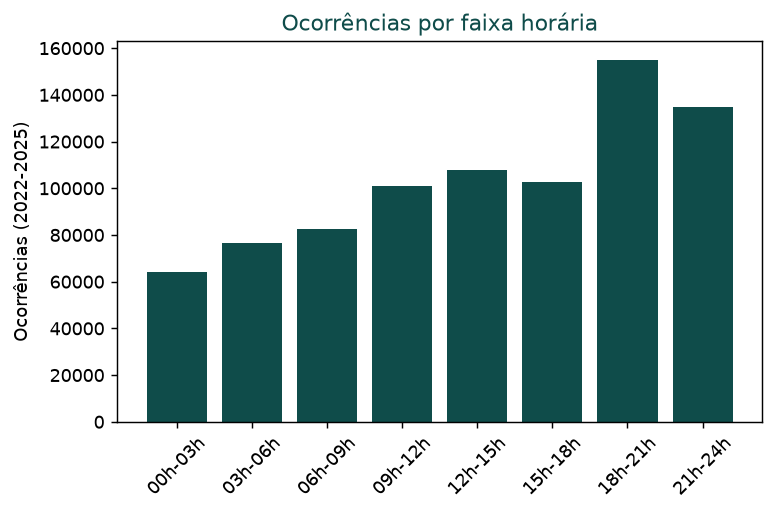

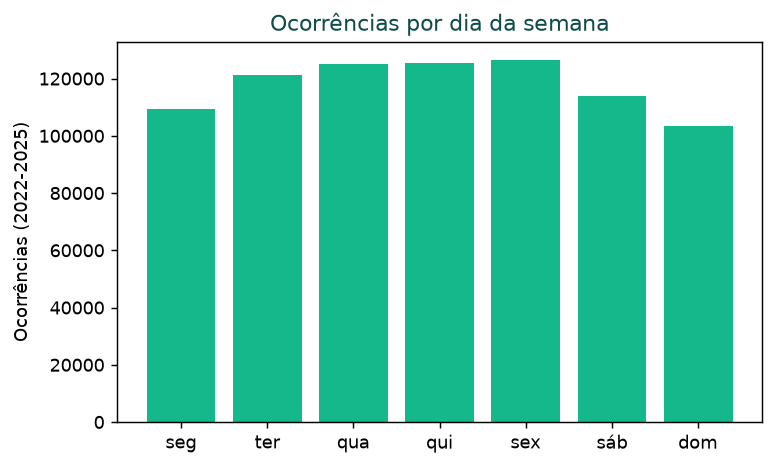

Faixa mais frequente: 18h-21h (18.8% das ocorrências); dia mais frequente: sex (15.3%).


In [4]:
oc, _ = ocorrencias_limpas()
oc = oc[pd.to_datetime(oc["data"]) >= "2022-01-01"]
faixa = (oc["hora"].astype(int) // 3).value_counts().sort_index()
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
dia = pd.to_datetime(oc["data"]).dt.day_of_week.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.bar([f"{3*i:02d}h-{3*i+3:02d}h" for i in faixa.index], faixa.to_numpy(), color="#0F4C4A")
ax.set_ylabel("Ocorrências (2022-2025)")
ax.set_title("Ocorrências por faixa horária", color="#0F4C4A")
ax.tick_params(axis="x", labelrotation=45)
fig.savefig(DIR_FIG / "explor_faixa.png", dpi=130, bbox_inches="tight")
plt.close(fig)
display(Image(DIR_FIG / "explor_faixa.png"))

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.bar([dias[i] for i in dia.index], dia.to_numpy(), color="#14B88A")
ax.set_ylabel("Ocorrências (2022-2025)")
ax.set_title("Ocorrências por dia da semana", color="#0F4C4A")
fig.savefig(DIR_FIG / "explor_dia.png", dpi=130, bbox_inches="tight")
plt.close(fig)
display(Image(DIR_FIG / "explor_dia.png"))

pico = faixa.idxmax()
print(f"Faixa mais frequente: {3*pico:02d}h-{3*pico+3:02d}h ({faixa.max() / faixa.sum():.1%} das ocorrências); "
      f"dia mais frequente: {dias[dia.idxmax()]} ({dia.max() / dia.sum():.1%}).")

### Decisão: grade de 500 m ou distrito

A regra do projeto (`decidir_resolucao`) escolhe a **grade de 500 m** quando pelo menos 70 % das linhas válidas têm coordenada utilizável
e há pelo menos 20 mil ocorrências usadas; senão cairia para o distrito (plano B). Com os dados reais:

In [5]:
base = resumo["linhas_lidas"] - sum(resumo[k] for k in ("descartadas_municipio", "descartadas_objeto", "descartadas_data", "descartadas_hora"))
print(f"coordenada utilizável: {resumo['usadas'] / base:.1%} (mínimo {COORD_MIN_FRACAO:.0%}); usadas: {resumo['usadas']:,}".replace(",", "."))
print("decisão:", decidir_resolucao(resumo))
assert decidir_resolucao(resumo) == "grade"

coordenada utilizável: 93.0% (mínimo 70%); usadas: 828.618
decisão: grade


## 02 Modelo e preparação

**Por que XGBoost.** Os dados são tabulares, com poucas variáveis numéricas e relações não lineares (hora × dia × local), e as classes são
**desbalanceadas** (a maioria das células é de risco baixo). Árvores com gradiente tratam isso bem, aceitam pesos por amostra
(usamos pesos balanceados) e dão **importância de variáveis**, o que ajuda a explicar o modelo ao cidadão.

**Por que Random Forest como baseline.** É o modelo de árvores mais simples e robusto para comparar: tem poucos hiperparâmetros, usa menos ajuste e
mostra se o ganho do XGBoost vem mesmo do boosting. Também usa pesos balanceados por classe.

**As 3 classes.** O alvo é a contagem de ocorrências de uma área em um trimestre, um dia da semana e uma faixa de 3 h. Os cortes são calculados
**só com o treino** (para o teste não vazar para as classes): entre as contagens maiores que zero, até o quantil 50 % é "baixo", até o 85 % é "médio" e acima disso é "alto".
Contagem zero cai em "baixo".

In [6]:
c1, c2 = ds.cortes
print(f"cortes: baixo <= {c1}; médio de {c1 + 1} a {c2}; alto > {c2}")
nomes = ["baixo", "médio", "alto"]
dist = pd.DataFrame({
    "treino": np.bincount(ds.y_treino, minlength=3),
    "teste": np.bincount(ds.y_teste, minlength=3),
}, index=nomes)
dist["treino %"] = (dist["treino"] / dist["treino"].sum() * 100).round(2)
dist["teste %"] = (dist["teste"] / dist["teste"].sum() * 100).round(2)
display(dist)

cortes: baixo <= 1; médio de 2 a 2; alto > 2


,treino,teste,treino %,teste %
baixo,1116212,407980,92.97,93.45
médio,57453,19875,4.79,4.55
alto,26919,8721,2.24,2.00


**Divisão temporal, sem embaralhar.** O treino usa os trimestres anteriores a `inicio_teste`; o teste usa os trimestres de 2025.
Misturar linhas ao acaso deixaria o modelo ver o futuro; aqui ele prevê períodos que nunca viu, como fará no app.
O `risco.csv` final representa o trimestre seguinte ao último completo.

In [7]:
print("início do teste:", info["inicio_teste"])
print("períodos completos:", info["periodos"][0], "a", info["periodos"][-1], "| trimestre previsto no risco.csv:", info["periodo_previsto"])
print(f"áreas ativas: {info['n_areas']:,} | linhas de treino: {info['n_treino']:,} | linhas de teste: {info['n_teste']:,} | linhas do futuro: {len(ds.X_futuro):,}".replace(",", "."))
print("treino:", ds.p_treino.min(), "a", ds.p_treino.max(), "| teste:", ds.p_teste.min(), "a", ds.p_teste.max())

assert ds.p_treino.max() < ds.inicio_teste
assert ds.p_teste.min() >= ds.inicio_teste
assert ds.cortes == calcular_cortes(info["contagem_treino"])
print("verificações passaram: nenhum período do treino é igual ou posterior ao início do teste, e os cortes vêm só do treino.")

início do teste: 2025T1
períodos completos: 2022T1 a 2025T4 | trimestre previsto no risco.csv: 2026T1
áreas ativas: 1.949 | linhas de treino: 1.200.584 | linhas de teste: 436.576 | linhas do futuro: 109.144


treino: 2022T2 a 2024T4 | teste: 2025T1 a 2025T4


verificações passaram: nenhum período do treino é igual ou posterior ao início do teste, e os cortes vêm só do treino.


**Variáveis (features).**

- *Estruturais da área e do contexto* (não mudam com a história de crimes): `lat`, `lng`, `dia_semana`, `faixa`, `trimestre`, `dist_estacao_m`, `dist_delegacia_m`
  (GeoSampa), `clima_temp_media`, `clima_chuva_mm` (Open-Meteo, mesmo trimestre; no futuro vale o do mesmo trimestre do ano anterior),
  `densidade_pop_hab_km2` (IBGE) e `iluminacao_n` (GeoSampa).
- *Defasadas* (histórico da própria área, sempre de períodos anteriores ao alvo): `cont_ant_1` (contagem no trimestre anterior, mesmo dia e faixa),
  `cont_ant_4` (média dos até 4 trimestres anteriores) e `area_ant_4` (média do total da área nos até 4 trimestres anteriores).

In [8]:
estruturais = [f for f in ds.features if not f.startswith(("cont_ant", "area_ant"))]
defasadas = [f for f in ds.features if f.startswith(("cont_ant", "area_ant"))]
print("estruturais:", estruturais)
print("defasadas:", defasadas)
display(ds.X_treino.describe().T[["mean", "std", "min", "max"]].round(2))

estruturais: ['lat', 'lng', 'dia_semana', 'faixa', 'trimestre', 'dist_estacao_m', 'dist_delegacia_m', 'clima_temp_media', 'clima_chuva_mm', 'densidade_pop_hab_km2', 'iluminacao_n']
defasadas: ['cont_ant_1', 'cont_ant_4', 'area_ant_4']


,mean,std,min,max
lat,-23.57,0.07,-23.77,-23.41
lng,-46.61,0.11,-46.80,-46.37
dia_semana,3.00,2.00,0.00,6.00
faixa,3.50,2.29,0.00,7.00
trimestre,2.64,1.07,1.00,4.00
dist_estacao_m,1656.52,1263.82,14.98,8774.47
dist_delegacia_m,1299.63,691.37,36.13,5747.79
clima_temp_media,19.44,3.68,11.74,27.86
clima_chuva_mm,0.43,0.59,0.00,4.52
cont_ant_1,0.39,0.86,0.00,57.00


## 03 Treino e avaliação

**Validação cruzada temporal.** A escolha dos hiperparâmetros usa só o treino, com janela expansiva sobre os trimestres:
cada rodada treina nos períodos mais antigos e valida nos seguintes (nunca o contrário). O teste fica intocado até o modelo final.
A métrica é o **F1 macro** (média do F1 das três classes), que não deixa a classe "baixo", muito mais numerosa, esconder erros na classe "alto".

In [9]:
splits = cv_temporal(ds.p_treino, 3)
for k, (tr, va) in enumerate(splits, 1):
    print(f"rodada {k}: treina em {ds.p_treino.iloc[tr].min()} a {ds.p_treino.iloc[tr].max()} ({len(tr):,} linhas); "
          f"valida em {ds.p_treino.iloc[va].min()} a {ds.p_treino.iloc[va].max()} ({len(va):,} linhas)".replace(",", "."))
    assert ds.p_treino.iloc[tr].max() < ds.p_treino.iloc[va].min()

rodada 1: treina em 2022T2 a 2023T2 (545.720 linhas); valida em 2023T3 a 2023T4 (218.288 linhas)


rodada 2: treina em 2022T2 a 2023T4 (764.008 linhas); valida em 2024T1 a 2024T2 (218.288 linhas)


rodada 3: treina em 2022T2 a 2024T2 (982.296 linhas); valida em 2024T3 a 2024T4 (218.288 linhas)


### XGBoost: 12 combinações sorteadas da grade

grade XGBoost: {'n_estimators': [100, 200, 400], 'max_depth': [3, 5, 7, 9], 'learning_rate': [0.03, 0.1, 0.3]} | combinações sorteadas: 12


,n_estimators,max_depth,learning_rate,f1_macro_cv,f1_desvio_cv,tempo_s
0,400,9,0.30,0.4587,0.0136,462.9539
1,200,9,0.30,0.4402,0.0133,260.3883
2,100,9,0.10,0.4206,0.0068,126.4632
3,200,7,0.30,0.4170,0.0081,160.6241
4,100,9,0.03,0.4169,0.0075,145.4917
5,400,7,0.03,0.4133,0.0028,375.5642
6,100,7,0.30,0.4128,0.0055,99.1779
7,200,5,0.10,0.4089,0.0010,136.1274
8,400,5,0.10,0.4084,0.0016,327.1574
9,100,3,0.10,0.4069,0.0028,49.6845


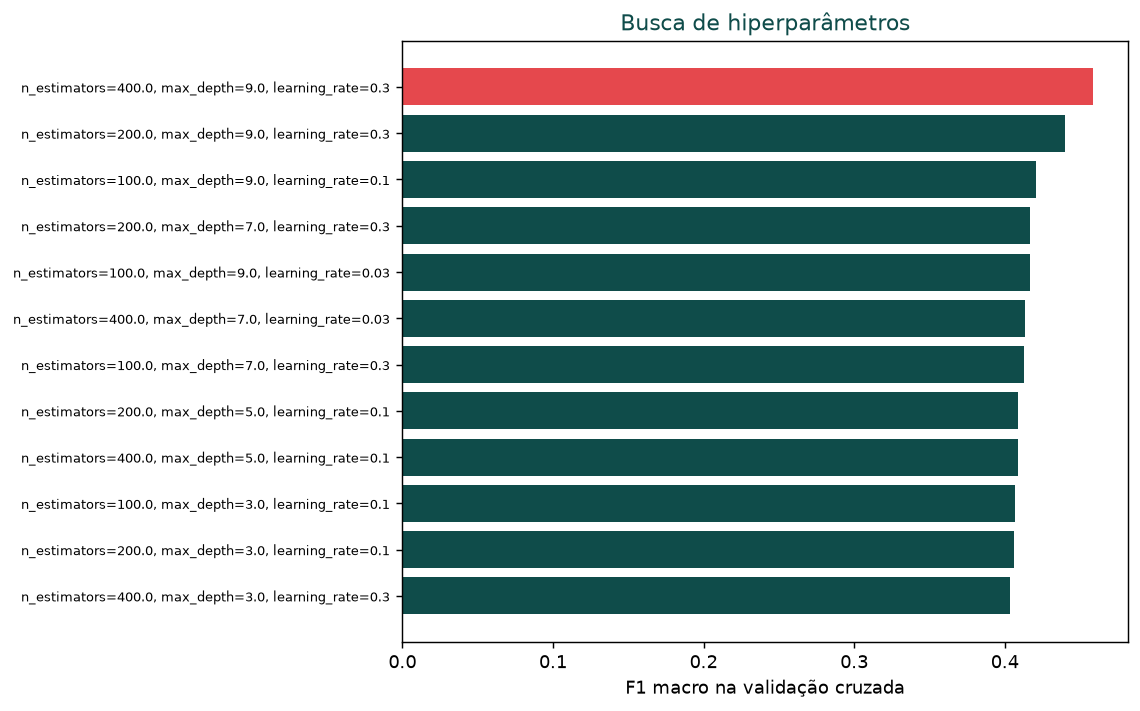

In [10]:
print("grade XGBoost:", GRADE_XGB, "| combinações sorteadas:", N_COMBINACOES_XGB)
busca_xgb = buscar_hiperparametros(fabrica_xgb, GRADE_XGB, ds.X_treino, ds.y_treino, splits, N_COMBINACOES_XGB)
pd.set_option("display.width", 200)
display(busca_xgb.round(4))
display(Image(grafico_busca(busca_xgb, DIR_FIG / "busca_xgb.png")))

### Random Forest (baseline): combinações sorteadas da grade

grade Random Forest: {'n_estimators': [100, 300], 'max_depth': [8, 16, None], 'min_samples_leaf': [1, 5, 20]} | combinações sorteadas: 4


,n_estimators,min_samples_leaf,max_depth,f1_macro_cv,f1_desvio_cv,tempo_s
0,100,5,16,0.4730,0.0101,301.9938
1,300,1,8,0.4204,0.0070,639.3482
2,100,1,8,0.4202,0.0066,203.4549
3,300,20,8,0.4197,0.0065,594.1305


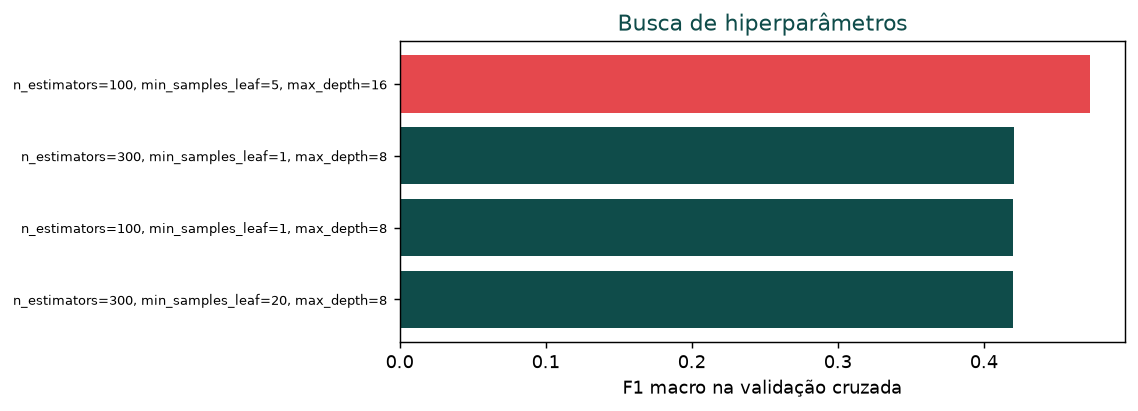

In [11]:
print("grade Random Forest:", GRADE_RF, "| combinações sorteadas:", N_COMBINACOES_RF)
busca_rf = buscar_hiperparametros(fabrica_rf, GRADE_RF, ds.X_treino, ds.y_treino, splits, N_COMBINACOES_RF)
display(busca_rf.round(4))
display(Image(grafico_busca(busca_rf, DIR_FIG / "busca_rf.png")))

In [12]:
COLUNAS_METRICA = {"f1_macro_cv", "f1_desvio_cv", "tempo_s"}


def melhores(tabela):
    params = {}
    for c in tabela.columns:
        if c in COLUNAS_METRICA:
            continue
        v = tabela[c].iloc[0]  # por coluna: iloc[0] da linha inteira viraria float e quebraria n_estimators e max_depth
        params[c] = None if v is None or (isinstance(v, float) and np.isnan(v)) else (v.item() if hasattr(v, "item") else v)
    return params


params_xgb = melhores(busca_xgb)
params_rf = melhores(busca_rf)
print("melhores parâmetros XGBoost:", params_xgb, f"| F1 macro CV = {busca_xgb.loc[0, 'f1_macro_cv']:.4f}")
print("melhores parâmetros Random Forest:", params_rf, f"| F1 macro CV = {busca_rf.loc[0, 'f1_macro_cv']:.4f}")

melhores parâmetros XGBoost: {'n_estimators': 400, 'max_depth': 9, 'learning_rate': 0.3} | F1 macro CV = 0.4587
melhores parâmetros Random Forest: {'n_estimators': 100, 'min_samples_leaf': 5, 'max_depth': 16} | F1 macro CV = 0.4730


## 04 Resultados e conclusão

Com os melhores hiperparâmetros de cada modelo, treino final em todo o treino e **uma única** avaliação no teste (os trimestres de 2025).

In [13]:
modelo_xgb = treinar_final(fabrica_xgb, params_xgb, ds.X_treino, ds.y_treino)
modelo_rf = treinar_final(fabrica_rf, params_rf, ds.X_treino, ds.y_treino)
res = {
    "xgb": {"treino": avaliar(modelo_xgb, ds.X_treino, ds.y_treino), "teste": avaliar(modelo_xgb, ds.X_teste, ds.y_teste)},
    "rf": {"treino": avaliar(modelo_rf, ds.X_treino, ds.y_treino), "teste": avaliar(modelo_rf, ds.X_teste, ds.y_teste)},
}
cv = {"xgb": float(busca_xgb.loc[0, "f1_macro_cv"]), "rf": float(busca_rf.loc[0, "f1_macro_cv"])}
tabela = pd.DataFrame({
    "F1 macro treino": {m: res[m]["treino"]["f1_macro"] for m in res},
    "F1 macro validação cruzada": cv,
    "F1 macro teste": {m: res[m]["teste"]["f1_macro"] for m in res},
    "acurácia teste": {m: res[m]["teste"]["accuracy"] for m in res},
})
tabela.index = ["XGBoost", "Random Forest"]
display(tabela.round(4))

,F1 macro treino,F1 macro validação cruzada,F1 macro teste,acurácia teste
XGBoost,0.6796,0.4587,0.4405,0.8169
Random Forest,0.5665,0.4730,0.4657,0.8312


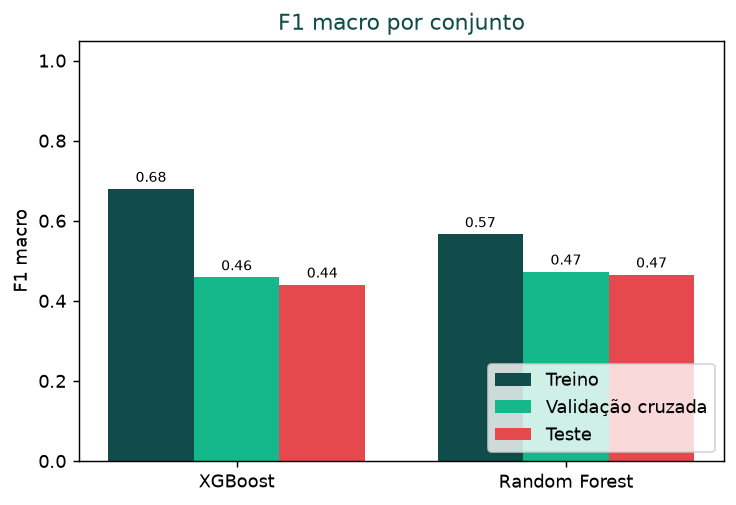

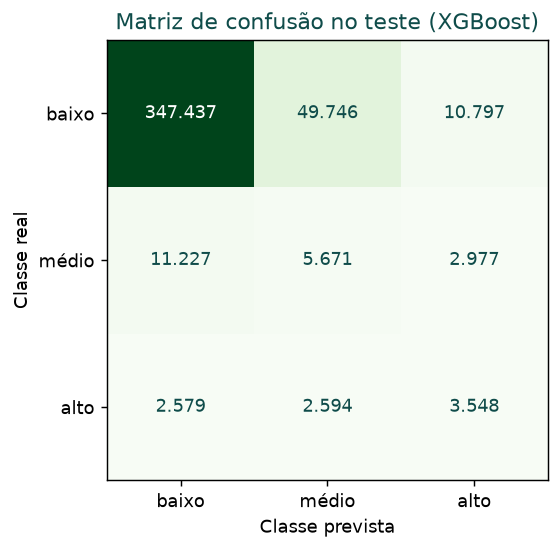

In [14]:
barras = {"XGBoost": {"treino": res["xgb"]["treino"]["f1_macro"], "cv": cv["xgb"], "teste": res["xgb"]["teste"]["f1_macro"]},
          "Random Forest": {"treino": res["rf"]["treino"]["f1_macro"], "cv": cv["rf"], "teste": res["rf"]["teste"]["f1_macro"]}}
display(Image(grafico_treino_teste(barras, DIR_FIG / "treino_teste.png")))
display(Image(grafico_matriz_confusao(res["xgb"]["teste"]["matriz"], DIR_FIG / "matriz_confusao_teste_xgb.png",
                                      "Matriz de confusão no teste (XGBoost)")))

,fracao,n_treino,f1_treino,f1_teste
0,0.2,240117,0.9005,0.4401
1,0.4,480234,0.8033,0.4538
2,0.6,720350,0.7529,0.4505
3,0.8,960467,0.7054,0.4435
4,1.0,1200584,0.6796,0.4405


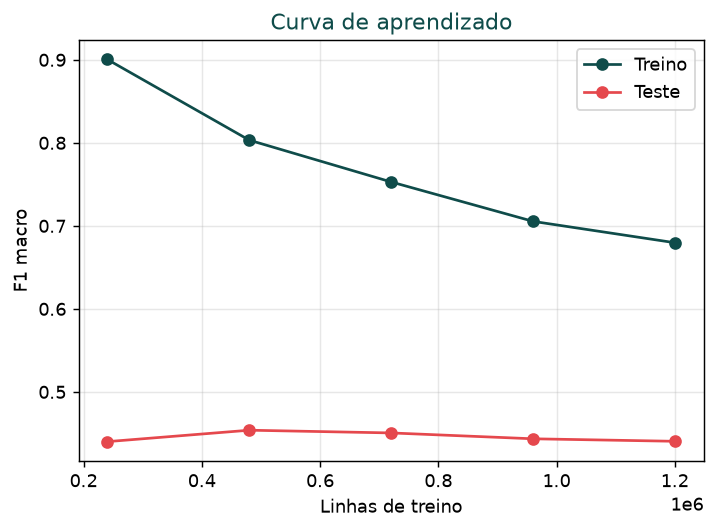

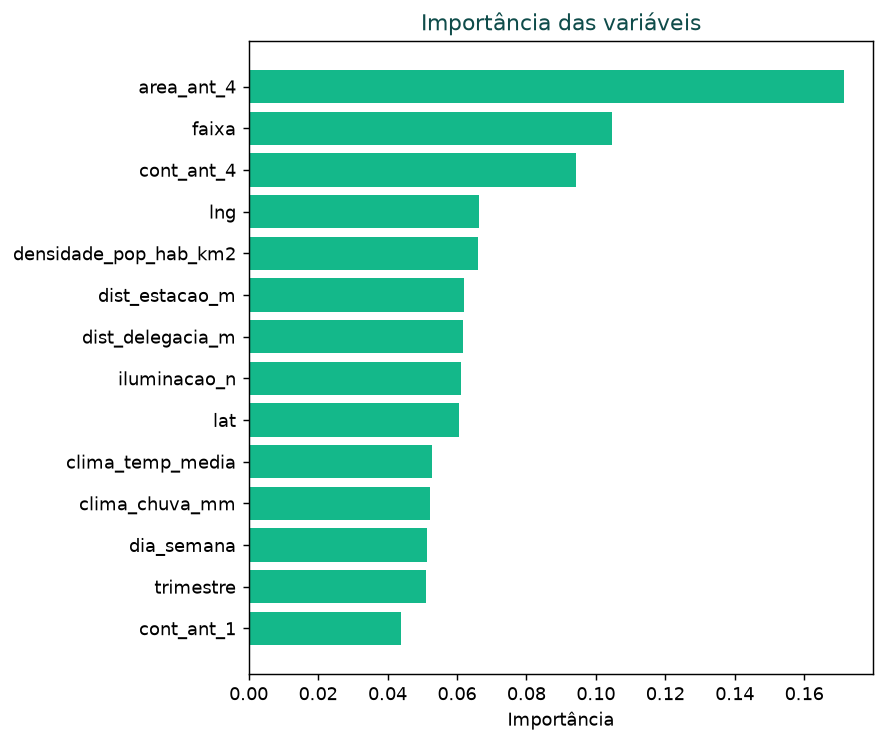

variáveis mais importantes: area_ant_4 (0.17), faixa (0.10), cont_ant_4 (0.09), lng (0.07), densidade_pop_hab_km2 (0.07)


In [15]:
curva = curva_aprendizado(fabrica_xgb, params_xgb, ds.X_treino, ds.y_treino, ds.X_teste, ds.y_teste)
display(curva.round(4))
display(Image(grafico_curva_aprendizado(curva, DIR_FIG / "curva_aprendizado.png")))
imp = pd.Series(modelo_xgb.feature_importances_, index=ds.features)
display(Image(grafico_importancia(imp, DIR_FIG / "importancia_xgb.png")))
print("variáveis mais importantes:", ", ".join(f"{k} ({v:.2f})" for k, v in imp.sort_values(ascending=False).head(5).items()))

### Overfitting: treino × teste

In [16]:
partes = []
for nome, chave in (("XGBoost", "xgb"), ("Random Forest", "rf")):
    f_tr, f_te = res[chave]["treino"]["f1_macro"], res[chave]["teste"]["f1_macro"]
    partes.append(f"- **{nome}:** F1 macro de treino {f_tr:.3f}, de teste {f_te:.3f}; diferença treino menos teste = **{f_tr - f_te:+.3f}**.")
dif_xgb = res["xgb"]["treino"]["f1_macro"] - res["xgb"]["teste"]["f1_macro"]
dif_rf = res["rf"]["treino"]["f1_macro"] - res["rf"]["teste"]["f1_macro"]
vencedor = "XGBoost" if res["xgb"]["teste"]["f1_macro"] >= res["rf"]["teste"]["f1_macro"] else "Random Forest"
leitura = ("A diferença é pequena: não há sinal forte de overfitting." if max(dif_xgb, dif_rf) < 0.05 else
           "Há uma queda do treino para o teste, o que indica algum overfitting. Parte dela é esperada: o teste são trimestres que o modelo nunca viu, "
           "e o comportamento da criminalidade muda no tempo (deriva).")
partes.append(f"\nNo teste, o melhor modelo é o **{vencedor}**. {leitura}")
display(Markdown("\n".join(partes)))

- **XGBoost:** F1 macro de treino 0.680, de teste 0.440; diferença treino menos teste = **+0.239**.
- **Random Forest:** F1 macro de treino 0.566, de teste 0.466; diferença treino menos teste = **+0.101**.

No teste, o melhor modelo é o **Random Forest**. Há uma queda do treino para o teste, o que indica algum overfitting. Parte dela é esperada: o teste são trimestres que o modelo nunca viu, e o comportamento da criminalidade muda no tempo (deriva).

### Leitura para o cidadão

O modelo não diz quem será vítima. Ele diz **onde e quando** o risco histórico de roubo ou furto em via pública é maior, por área de 500 m, dia da semana e faixa de 3 horas.
No app, isso aparece como um mapa de risco por área e horário. As 10 combinações com maior probabilidade de risco alto no próximo trimestre:

In [17]:
risco = gerar_risco(modelo_xgb, ds.X_futuro, ds.chave_futuro)
dias_nome = ["segunda", "terça", "quarta", "quinta", "sexta", "sábado", "domingo"]
top = risco.sort_values("prob_alto", ascending=False, kind="stable").head(10).copy()
top["dia"] = top["dia_semana"].map(lambda d: dias_nome[d])
top["horário"] = top["faixa"].map(lambda f: f"{3*f:02d}h às {3*f+3:02d}h")
top["prob_alto"] = top["prob_alto"].round(3)
display(top[["area_id", "lat", "lng", "dia", "horário", "classe", "prob_alto"]].reset_index(drop=True))
print(f"Trimestre previsto: {info['periodo_previsto']}. Classes no risco.csv:", risco["classe"].value_counts().to_dict())

,area_id,lat,lng,dia,horário,classe,prob_alto
0,g054_041,-23.55475,-46.62665,quarta,18h às 21h,alto,1.000
1,g054_040,-23.55475,-46.63155,domingo,12h às 15h,alto,1.000
2,g050_038,-23.57275,-46.64135,sexta,18h às 21h,alto,0.999
3,g054_040,-23.55475,-46.63155,quarta,18h às 21h,alto,0.998
4,g054_037,-23.55475,-46.64625,sábado,03h às 06h,alto,0.998
5,g054_041,-23.55475,-46.62665,sexta,18h às 21h,alto,0.997
6,g054_037,-23.55475,-46.64625,domingo,00h às 03h,alto,0.997
7,g054_043,-23.55475,-46.61685,sexta,18h às 21h,alto,0.997
8,g058_043,-23.53675,-46.61685,sábado,09h às 12h,alto,0.997
9,g050_038,-23.57275,-46.64135,quarta,18h às 21h,alto,0.997


Trimestre previsto: 2026T1. Classes no risco.csv: {'baixo': 95084, 'medio': 10900, 'alto': 3160}


### Exportação final

O modelo final é o XGBoost treinado no treino completo. `salvar_risco` valida o arquivo (56 combinações de dia × faixa por área, `prob_alto` entre 0 e 1,
centro de cada área coerente com o `area_id`) antes de gravar `ml/saida/risco.csv`, que a API lê. Em seguida o notebook grava `ml/saida/metricas.json`.

In [18]:
import json

destino = salvar_risco(risco)
print("gravado:", destino, "|", len(risco), "linhas")


def bloco(chave, params, tabela_busca):
    return {
        "melhores_params": params,
        "f1_macro_treino": res[chave]["treino"]["f1_macro"],
        "f1_macro_cv": float(tabela_busca.loc[0, "f1_macro_cv"]),
        "f1_macro_teste": res[chave]["teste"]["f1_macro"],
        "accuracy_teste": res[chave]["teste"]["accuracy"],
        "matriz_teste": res[chave]["teste"]["matriz"],
    }


metricas = {
    "xgb": bloco("xgb", params_xgb, busca_xgb),
    "rf": bloco("rf", params_rf, busca_rf),
    "cortes": [int(c) for c in ds.cortes],
    "inicio_teste": ds.inicio_teste,
    "n_treino": int(info["n_treino"]),
    "n_teste": int(info["n_teste"]),
    "n_areas": int(info["n_areas"]),
    "periodos": info["periodos"],
    "periodo_previsto": info["periodo_previsto"],
    "n_combinacoes_xgb": int(len(busca_xgb)),
    "n_combinacoes_rf": int(len(busca_rf)),
}
(DIR_SAIDA / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print((DIR_SAIDA / "metricas.json").read_text(encoding="utf-8"))

gravado: C:\Users\pedro.martins\Documents\Projetos claude\Ampara\ml\saida\risco.csv | 109144 linhas
{
  "xgb": {
    "melhores_params": {
      "n_estimators": 400,
      "max_depth": 9,
      "learning_rate": 0.3
    },
    "f1_macro_treino": 0.6796373582539063,
    "f1_macro_cv": 0.45874164211758295,
    "f1_macro_teste": 0.44048028778525666,
    "accuracy_teste": 0.8169390896430404,
    "matriz_teste": [
      [
        347437,
        49746,
        10797
      ],
      [
        11227,
        5671,
        2977
      ],
      [
        2579,
        2594,
        3548
      ]
    ]
  },
  "rf": {
    "melhores_params": {
      "n_estimators": 100,
      "min_samples_leaf": 5,
      "max_depth": 16
    },
    "f1_macro_treino": 0.5664553257165971,
    "f1_macro_cv": 0.4729867730847333,
    "f1_macro_teste": 0.4656848756882314,
    "accuracy_teste": 0.831202356519827,
    "matriz_teste": [
      [
        352841,
        45782,
        9357
      ],
      [
        10732,
        5

### Conclusão

O pipeline leu dados reais da SSP-SP, GeoSampa, Open-Meteo e IBGE, montou um painel por área de 500 m, trimestre, dia da semana e faixa horária,
e comparou XGBoost com Random Forest em validação cruzada temporal, medindo o resultado final em trimestres que o modelo nunca viu.
Os números exatos estão nas tabelas acima e em `ml/saida/metricas.json`.

**Limitações.** O alvo é um proxy (roubo ou furto em via pública), porque a SSP não separa celular. Boletins sem hora ou sem coordenada ficam fora.
Ocorrência registrada não é ocorrência real (há subnotificação), e a polícia registra mais onde há mais policiamento. O clima usa um ponto só para a cidade.
O risco é histórico e coletivo: serve para informar rotas e horários, não para julgar pessoas ou bairros.